In [1]:
# Imports
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load FRED monthly series from Triple 1
DATA_DIR = Path("data") / "Triple 1"  # relative to RecPlay/, where this notebook lives

def load_csv(name: str) -> pd.Series:
    df = pd.read_csv(DATA_DIR / f"{name}.csv", parse_dates=["observation_date"], index_col="observation_date")
    return df[name].astype(float)

cpi = load_csv("CPIAUCSL")
unrate = load_csv("UNRATE")
fedfunds = load_csv("FEDFUNDS")

for s in (cpi, unrate, fedfunds):
    print(f"{s.name:9s} {s.index.min().date()} to {s.index.max().date()}  n={len(s)}  missing={s.isna().sum()}")

CPIAUCSL  1947-01-01 to 2026-09-01  n=957  missing=1
UNRATE    1948-01-01 to 2026-09-01  n=945  missing=1
FEDFUNDS  1954-07-01 to 2026-09-01  n=867  missing=0


In [3]:
# Impute October 2025 as Bureau of labor stats did not collect CPI or household-survey data during the shutdown

cpi_m, unrate_m, fedfunds_m = (s.asfreq("MS") for s in (cpi, unrate, fedfunds))

cpi_imputed = cpi_m.isna()
unrate_imputed = unrate_m.isna()

print("Imputing CPI at:", list(cpi_m.index[cpi_imputed].date))
print("Imputing UNRATE at:", list(unrate_m.index[unrate_imputed].date))
assert not fedfunds_m.isna().any()

cpi_clean = np.exp(np.log(cpi_m).interpolate(method="linear", limit_area="inside"))  # geometric for a price level
unrate_clean = unrate_m.interpolate(method="linear", limit_area="inside")
fedfunds_clean = fedfunds_m

print(pd.DataFrame({"CPIAUCSL": cpi_clean, "UNRATE": unrate_clean}).loc["2025-09":"2025-11"])

Imputing CPI at: [datetime.date(2025, 10, 1)]
Imputing UNRATE at: [datetime.date(2025, 10, 1)]
                    CPIAUCSL  UNRATE
observation_date                    
2025-09-01        324.245000    4.40
2025-10-01        324.653742    4.45
2025-11-01        325.063000    4.50


In [4]:
# CPI level turned to YoY inflation, on the full CPI history (1947-), thus no lost months at the 1954 start
# YoY inflation instead of MoM inflation, avoiding overly noisy periods 
inflation = (100 * (np.log(cpi_clean) - np.log(cpi_clean.shift(12)))).rename("INFLATION")

# A YoY value is imputed if either of its two CPI inputs was imputed
inflation_imputed = cpi_imputed | cpi_imputed.shift(12, fill_value=False)

inflation = inflation.dropna()
inflation_imputed = inflation_imputed.loc[inflation.index]
print(f"INFLATION {inflation.index.min().date()} to {inflation.index.max().date()}  n={len(inflation)}")

INFLATION 1948-01-01 to 2026-09-01  n=945


In [5]:
# Common window, checks
macro = pd.concat([inflation, unrate_clean, fedfunds_clean], axis=1, join="inner")
macro["IMPUTED"] = (inflation_imputed | unrate_imputed).loc[macro.index]

assert macro.index.is_monotonic_increasing and macro.index.is_unique
assert len(macro.asfreq("MS")) == len(macro), "gap in monthly index"
assert not macro.isna().any().any(), "NaN left after cleaning"

print(f"{macro.index.min().date()} to {macro.index.max().date()}  n={len(macro)}")
print("Imputed rows:", list(macro.index[macro["IMPUTED"]].date))
macro.head()

1954-07-01 to 2026-09-01  n=867
Imputed rows: [datetime.date(2025, 10, 1)]


,INFLATION,UNRATE,FEDFUNDS,IMPUTED
observation_date,,,,
1954-07-01,0.260951,5.8,0.80,False
1954-08-01,0.000000,6.0,1.22,False
1954-09-01,-0.297952,6.1,1.07,False
1954-10-01,-0.857095,5.7,0.85,False
1954-11-01,-0.261048,5.3,0.83,False


                min    min_date       max    max_date
INFLATION -1.978199  2009-07-01  13.62102  1980-03-01
UNRATE     3.400000  1968-09-01  14.80000  2020-04-01
FEDFUNDS   0.050000  2020-04-01  19.10000  1981-06-01


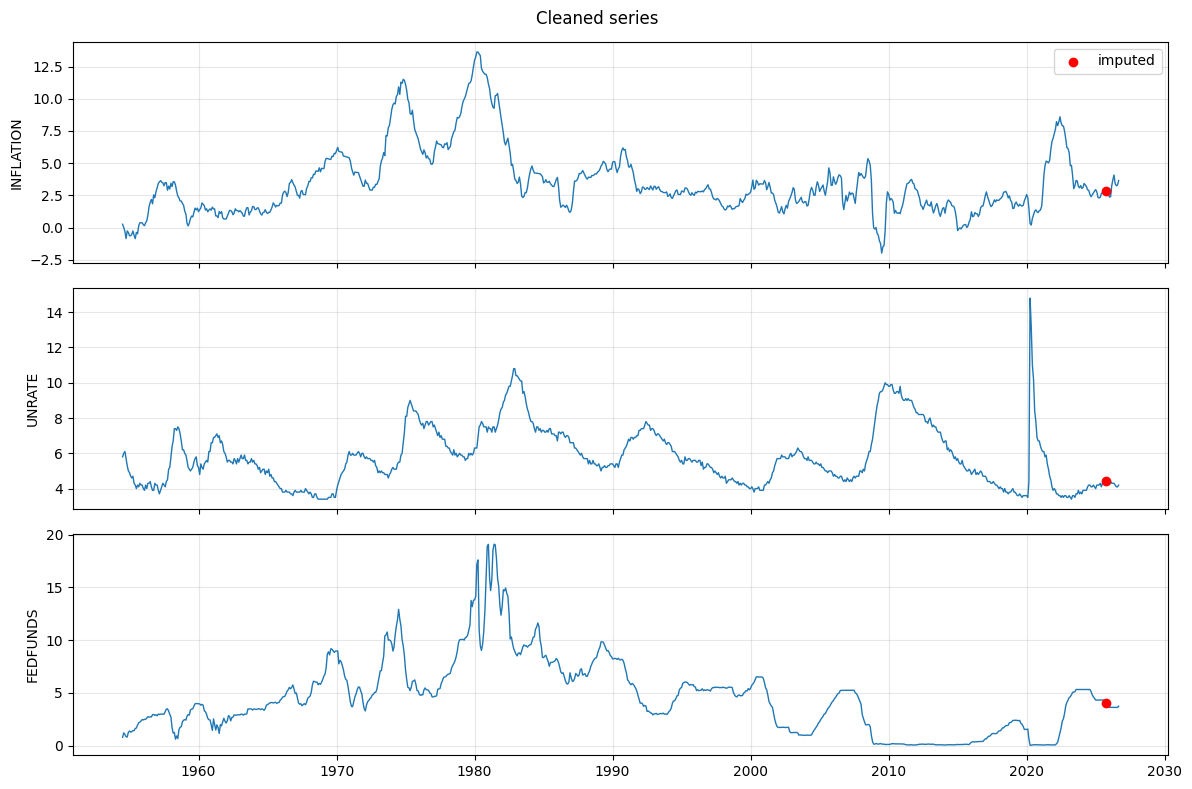

In [6]:
## We report extremes as well.

series_cols = ["INFLATION", "UNRATE", "FEDFUNDS"]
extremes = pd.DataFrame({
    "min": macro[series_cols].min(),
    "min_date": macro[series_cols].idxmin().dt.date,
    "max": macro[series_cols].max(),
    "max_date": macro[series_cols].idxmax().dt.date,
})
print(extremes)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, col in zip(axes, series_cols):
    ax.plot(macro.index, macro[col], lw=1)
    ax.scatter(macro.index[macro["IMPUTED"]], macro.loc[macro["IMPUTED"], col], color="red", zorder=3, label="imputed")
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper right")
fig.suptitle("Cleaned series")
fig.tight_layout()
plt.show()

In [7]:
# Recurrence plot setup: Euclidean distance on z-scored, delay-embedded series over the full 1954-2026 window.
# The threshold is set per series by a fixed recurrence rate, so the three RPs are equally dense
# despite having different units and ranges.
from matplotlib import dates as mdates

M, TAU = 1, 1      # embedding dimension and delay (months); m = 1 means the state is the value itself
RR_TARGET = 0.10   # share of off-diagonal pairs counted as recurrent

def embed(x: np.ndarray, m: int, tau: int) -> np.ndarray:
    n = len(x) - (m - 1) * tau
    return np.column_stack([x[i * tau : i * tau + n] for i in range(m)])

def recurrence(series: pd.Series, m: int = M, tau: int = TAU, rr: float = RR_TARGET):
    x = series.to_numpy(dtype=float)
    X = embed((x - x.mean()) / x.std(), m, tau)
    D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=-1))
    upper = np.triu_indices(len(D), k=1)
    eps = np.quantile(D[upper], rr)
    R = D <= eps
    dates = series.index[(m - 1) * tau :]  # each embedded state is dated by its latest month
    return D, R, eps, dates

def format_date_axes(a) -> None:
    for axis in (a.xaxis, a.yaxis):
        axis.set_major_locator(mdates.YearLocator(10))
        axis.set_major_formatter(mdates.DateFormatter("%Y"))
    a.set_xlabel("month j")
    a.set_ylabel("month i")

def plot_rp(series: pd.Series, m: int = M, tau: int = TAU, rr: float = RR_TARGET) -> np.ndarray:
    D, R, eps, dates = recurrence(series, m, tau, rr)
    actual_rr = R[np.triu_indices(len(R), k=1)].mean()  # ties at eps can push this above the target
    t0, t1 = mdates.date2num(dates[0]), mdates.date2num(dates[-1])
    extent = (t0, t1, t0, t1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
    im = ax[0].imshow(D, cmap="gist_earth", origin="lower", interpolation="nearest", extent=extent)
    fig.colorbar(im, ax=ax[0], fraction=0.046, pad=0.04, label="distance (std units)")
    ax[0].set_title("Distance matrix")
    ax[1].imshow(R, cmap="copper", origin="lower", interpolation="nearest", extent=extent)
    ax[1].set_title(f"Recurrence plot, ε = {eps:.3f} (RR = {actual_rr:.3f})")
    for a in ax:
        format_date_axes(a)
    fig.suptitle(f"{series.name}: EucD, m = {m}, τ = {tau}, {dates[0]:%Y-%m} to {dates[-1]:%Y-%m}, n = {len(dates)}")
    fig.tight_layout()
    plt.show()
    return R

rps = {}

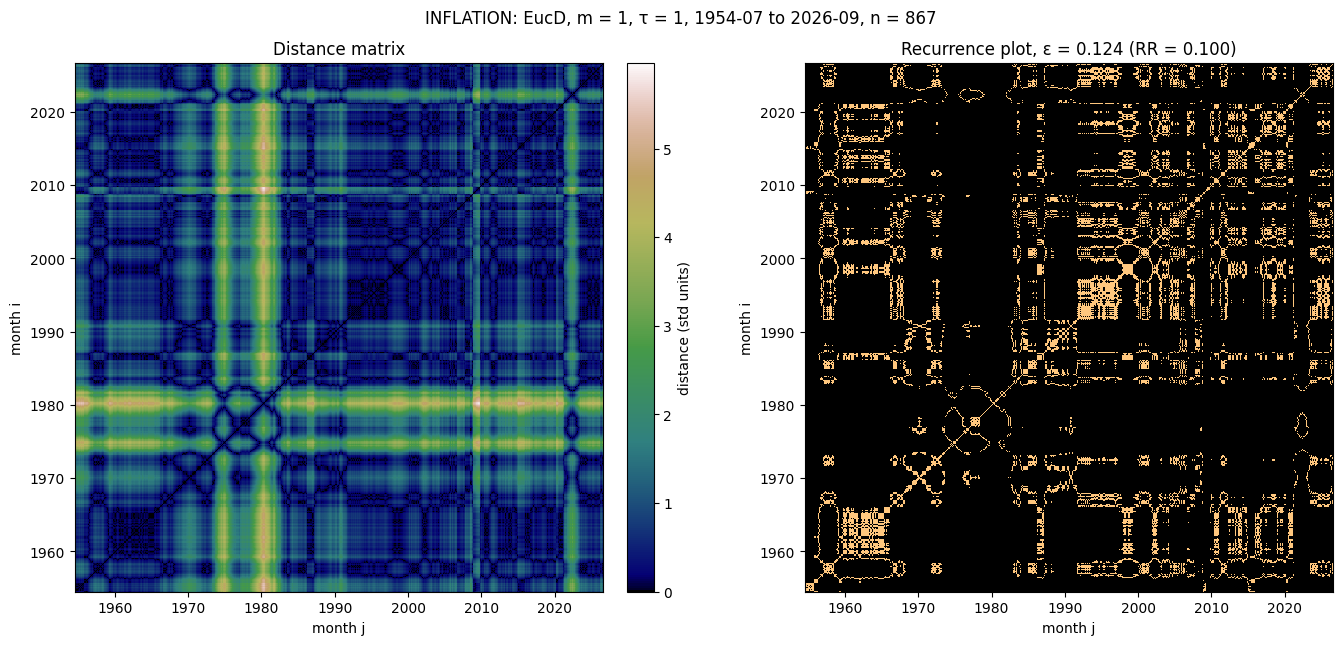

In [8]:
# Inflation RP
rps["INFLATION"] = plot_rp(macro["INFLATION"])

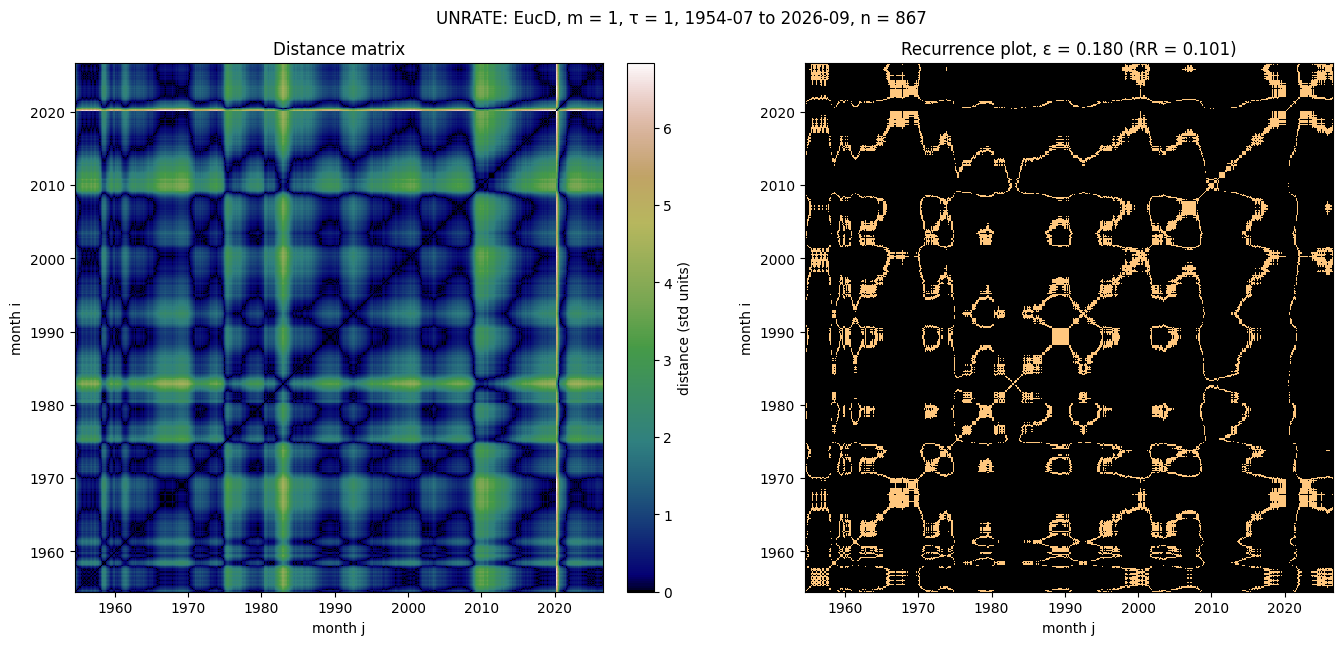

In [9]:
# Unemployment RP
rps["UNRATE"] = plot_rp(macro["UNRATE"])

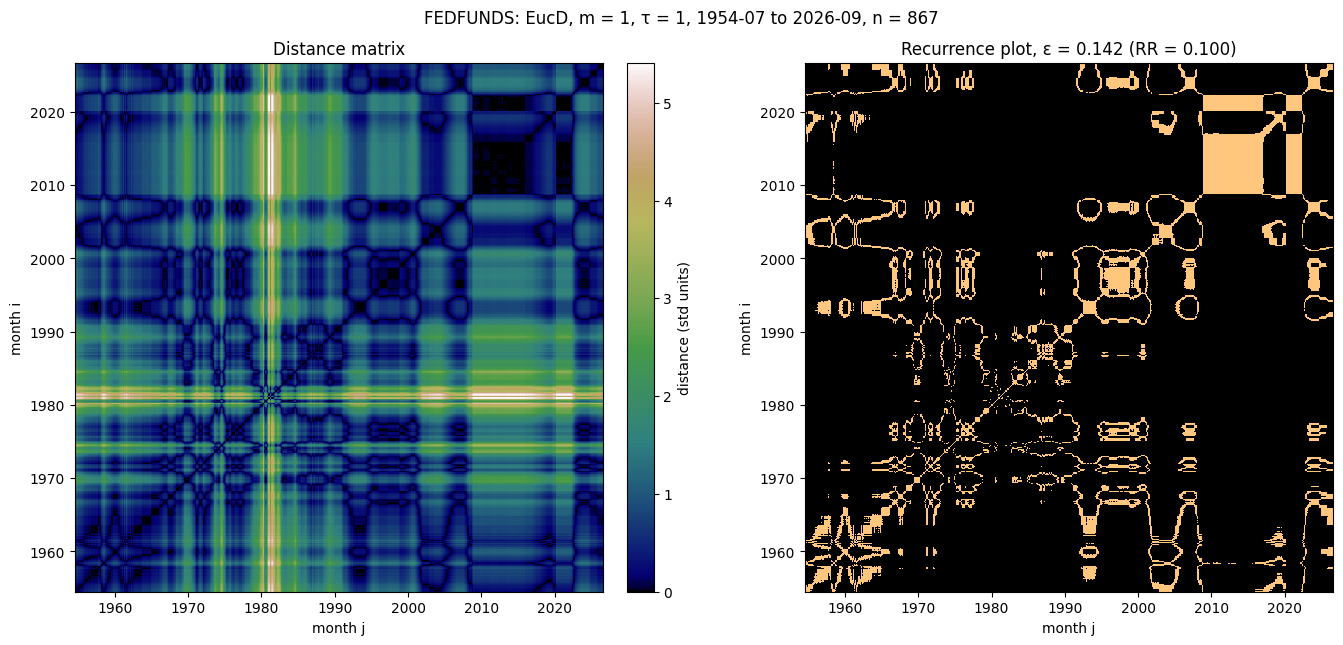

In [10]:
# Fed funds RP
rps["FEDFUNDS"] = plot_rp(macro["FEDFUNDS"])

In [11]:
# Recurrence independence, per pair and for the trio.
# If the series recurred independently, a month pair (i, j) would be jointly recurrent with probability
# equal to the product of the individual recurrence rates. ratio = observed joint RR / that product
# (1 = no more co-recurrence than chance; > 1 = they revisit their past states together).
from itertools import combinations

UPPER = np.triu_indices(len(macro) - (M - 1) * TAU, k=1)  # off-diagonal pairs, each counted once
rr = {name: R[UPPER].mean() for name, R in rps.items()}

rows = []
for k in (2, 3):
    for combo in combinations(series_cols, k):
        joint_rr = np.logical_and.reduce([rps[c] for c in combo])[UPPER].mean()
        expected_rr = np.prod([rr[c] for c in combo])
        rows.append({"systems": " × ".join(combo),
                     **{f"RR {c}": rr[c] for c in combo},
                     "joint RR": joint_rr,
                     "expected if independent": expected_rr,
                     "ratio": joint_rr / expected_rr})
independence = pd.DataFrame(rows).set_index("systems")
independence = independence[[f"RR {c}" for c in series_cols] + ["joint RR", "expected if independent", "ratio"]]
independence

,RR INFLATION,RR UNRATE,RR FEDFUNDS,joint RR,expected if independent,ratio
systems,,,,,,
INFLATION × UNRATE,0.100002,0.10082,NaN,0.013902,0.010082,1.378867
INFLATION × FEDFUNDS,0.100002,NaN,0.10001,0.016736,0.010001,1.673418
UNRATE × FEDFUNDS,NaN,0.10082,0.10001,0.014118,0.010083,1.400156
INFLATION × UNRATE × FEDFUNDS,0.100002,0.10082,0.10001,0.004840,0.001008,4.800041


In [12]:
# Pair RPs: joint recurrence. 
# Months (i, j) are jointly recurrent when BOTH series recur there: JR = R_X AND R_Y.
# Each series keeps its own ε from cell 6, so different units never get mixed in one distance.
# Cross RPs (X at month i vs Y at month j) are not used: they need both series in one shared state space.
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

OVERLAY_CMAP = ListedColormap(["black", "tab:blue", "tab:orange", "white"])

def plot_jrp(a: str, b: str) -> np.ndarray:
    Ra, Rb = rps[a], rps[b]
    JR = Ra & Rb
    stats = independence.loc[f"{a} × {b}"]
    dates = macro.index[(M - 1) * TAU :]
    t0, t1 = mdates.date2num(dates[0]), mdates.date2num(dates[-1])
    extent = (t0, t1, t0, t1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
    overlay = Ra.astype(int) + 2 * Rb.astype(int)  # 0 neither, 1 a only, 2 b only, 3 both
    ax[0].imshow(overlay, cmap=OVERLAY_CMAP, vmin=-0.5, vmax=3.5, origin="lower", interpolation="nearest", extent=extent)
    ax[0].legend(handles=[Patch(color="tab:blue", label=f"{a} only"),
                          Patch(color="tab:orange", label=f"{b} only"),
                          Patch(facecolor="white", edgecolor="grey", label="both")],
                 loc="upper left", fontsize=8, framealpha=0.9)
    ax[0].set_title("Individual RPs overlaid")
    ax[1].imshow(JR, cmap="copper", origin="lower", interpolation="nearest", extent=extent)
    ax[1].set_title(f"Joint recurrence plot, RR = {stats['joint RR']:.4f} ({stats['ratio']:.1f}× independence)")
    for x in ax:
        format_date_axes(x)
    fig.suptitle(f"{a} × {b}: EucD, m = {M}, τ = {TAU}, {dates[0]:%Y-%m} to {dates[-1]:%Y-%m}, n = {len(dates)}")
    fig.tight_layout()
    plt.show()
    return JR

jrps = {}

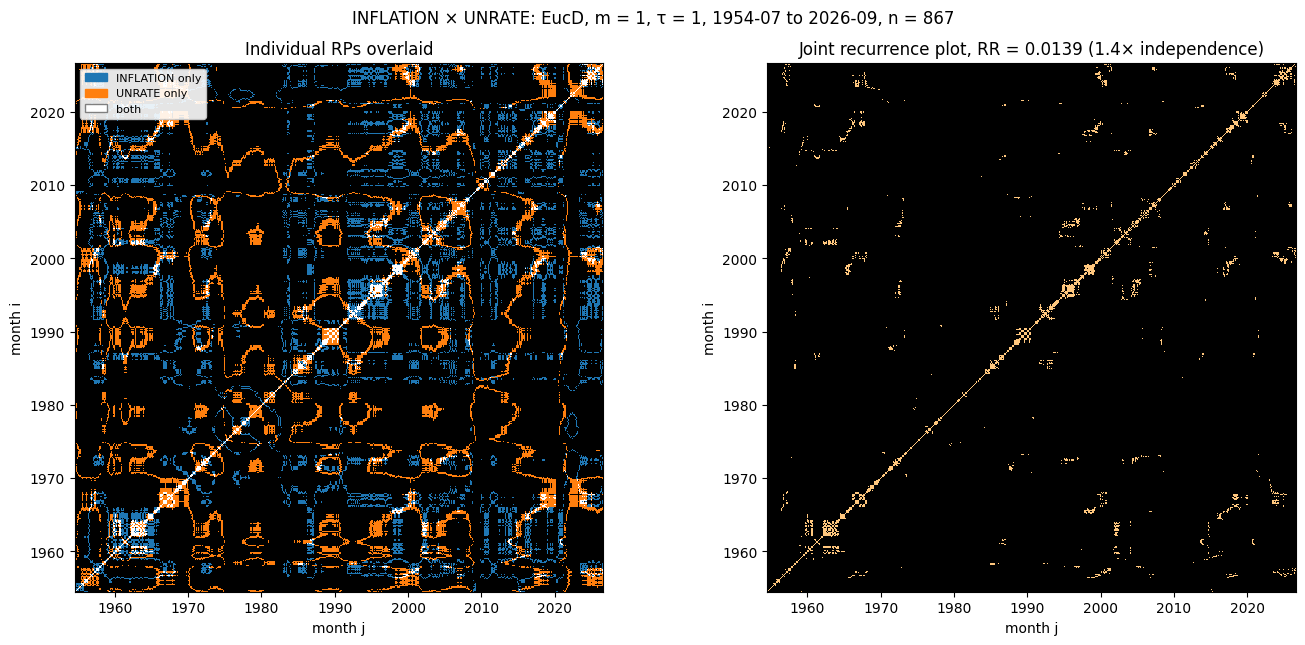

In [13]:
# Inflation x Unemployment JRP
jrps[("INFLATION", "UNRATE")] = plot_jrp("INFLATION", "UNRATE")

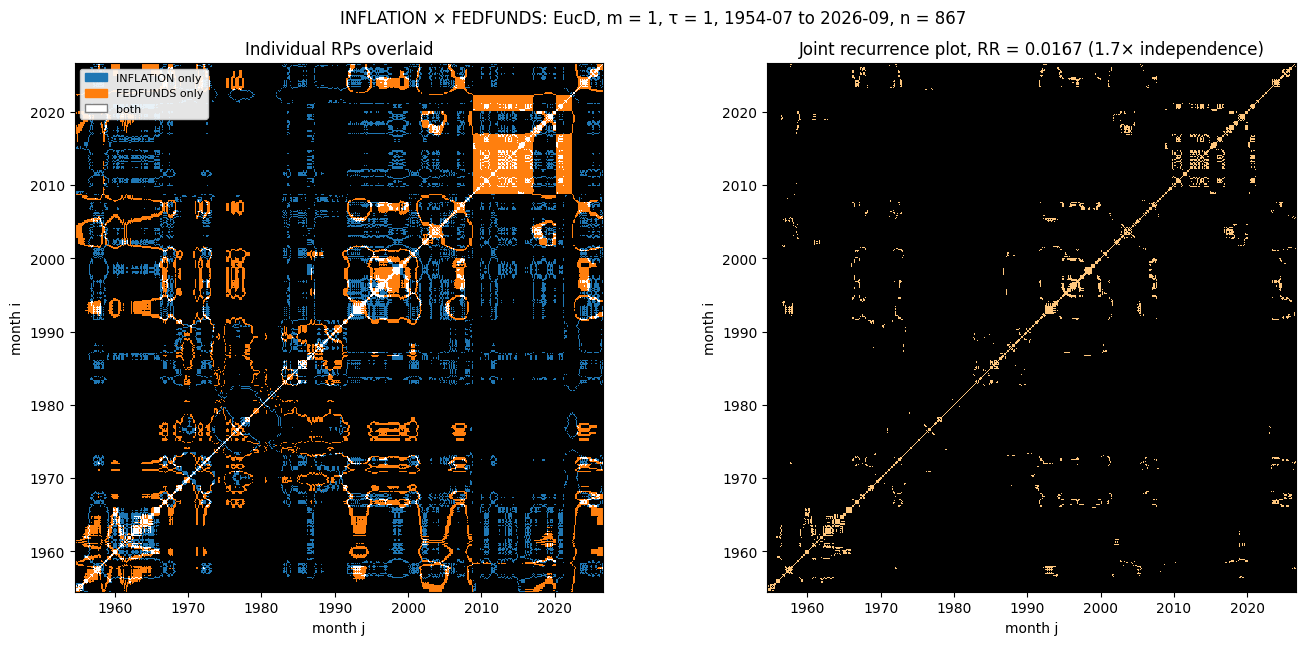

In [14]:
# Inflation x Fed funds JRP
jrps[("INFLATION", "FEDFUNDS")] = plot_jrp("INFLATION", "FEDFUNDS")

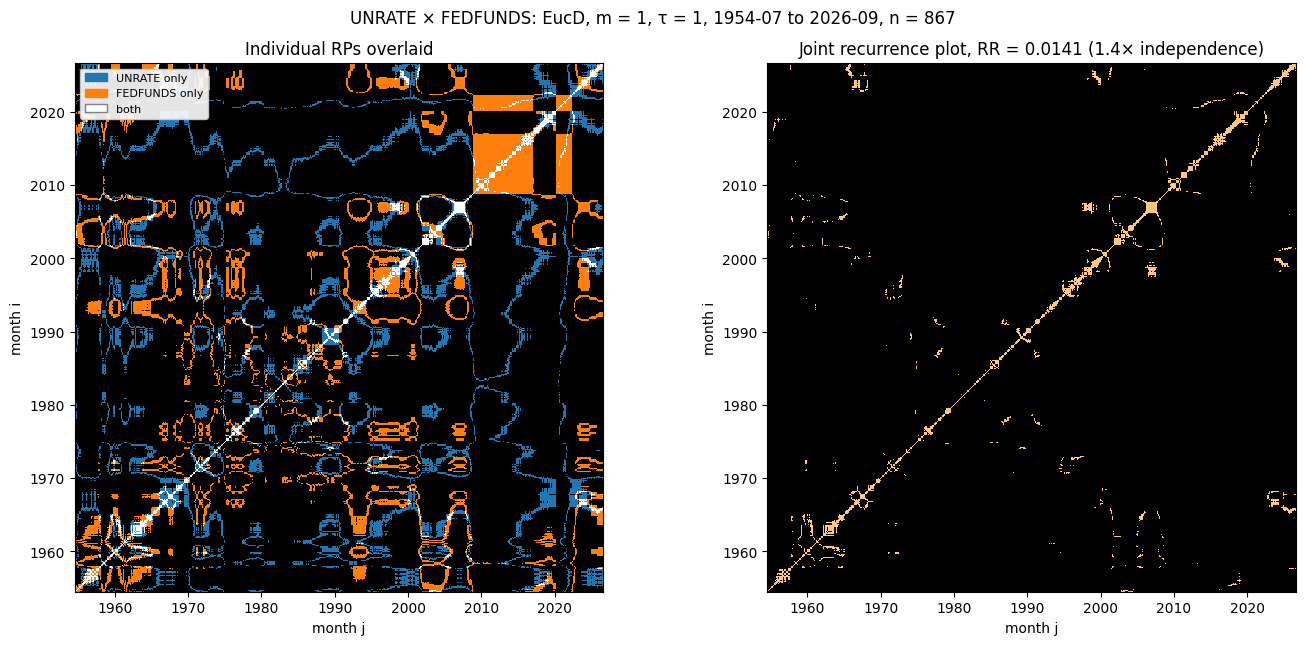

In [15]:
# Unemployment x Fed funds JRP
jrps[("UNRATE", "FEDFUNDS")] = plot_jrp("UNRATE", "FEDFUNDS")